# Estudo: análise exploratória, correlação e PCA — BRs de SC (PRF 2025)

Estudo complementar ao `previsao_acidentes_sc.ipynb`, usando **a mesma base de modelagem do projeto**
(trecho de 10 km × dia × período de 6 h, com clima do Open-Meteo) e o mesmo split temporal
(treino jan–set/2025, teste out–dez/2025).

Roteiro:
1. **Análise exploratória** — quando, onde, como e com que tempo acontecem os acidentes.
2. **Correlação** — como as features se relacionam entre si e com o alvo; redundância (multicolinearidade).
3. **PCA exploratório** — quanta informação cabe em poucos componentes e o que cada um representa.
4. **Modelos sem PCA × com PCA** — regressão logística e o HistGradientBoosting do projeto, com e sem PCA.

> Alvo: `teve_acidente` = 1 se houve **ao menos um acidente** no trecho naquele dia e período.

## 0. Setup e carga dos dados

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

sys.path.insert(0, "backend")  # reaproveita o código do projeto (mesma base, features e métricas)
from app import clima, config, dados
from app.features import ALVO, FEATURES, FEATURES_CAT, FEATURES_CLIMA, preparar_X
from scripts.treinar import avaliar, montar_base, novo_modelo

warnings.filterwarnings("ignore", category=FutureWarning)
# NumPy + Accelerate (macOS) emite avisos falsos de "overflow/divide by zero in matmul"; os resultados não são afetados
warnings.filterwarnings("ignore", category=RuntimeWarning, message=".*encountered in matmul")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
SEMENTE = 42

In [2]:
artefatos = config.REDES["br"]
acidentes = pd.read_parquet(artefatos.acidentes)      # uma linha por acidente (gerado por scripts.preparar_dados)
clima_hist = pd.read_parquet(artefatos.clima)         # clima por célula × dia × período (Open-Meteo)
trechos = dados.resumo_trechos(acidentes)

base = montar_base(acidentes, trechos, clima_hist)     # a mesma função do treino do projeto
CORTE = config.CORTE_TESTE["br"]
treino, teste = base[base["data"] < CORTE], base[base["data"] >= CORTE]

FEATS = FEATURES["br"]
CATS = FEATURES_CAT["br"]
NUMS = [f for f in FEATS if f not in CATS]
print(f"{len(acidentes):,} acidentes | {len(trechos)} trechos | base {len(base):,} linhas "
      f"(treino {len(treino):,}, teste {len(teste):,})")
print(f"{len(NUMS)} features numéricas: {NUMS}")
print(f"categóricas: {CATS}")

8,176 acidentes | 240 trechos | base 350,400 linhas (treino 262,080, teste 88,320)
16 features numéricas: ['trecho_km', 'lat', 'lon', 'periodo_idx', 'dia_semana', 'mes', 'fim_de_semana', 'feriado', 'vespera_ou_pos_feriado', 'temporada_verao', 'chuva_mm', 'nebulosidade', 'temperatura', 'taxa_historica', 'taxa_historica_periodo', 'acid_ult_90d']
categóricas: ['br', 'delegacia']


## 1. Análise exploratória

### 1.1 Volume e gravidade

In [3]:
resumo = pd.Series({
    "acidentes": len(acidentes),
    "BRs": acidentes["br"].nunique(),
    "trechos de 10 km": acidentes["trecho_id"].nunique(),
    "mortos": int(acidentes["mortos"].sum()),
    "feridos graves": int(acidentes["feridos_graves"].sum()),
    "acidentes com morte": int((acidentes["mortos"] > 0).sum()),
    "% de períodos com acidente (base)": f"{base[ALVO].mean():.2%}",
}, name="valor")
display(resumo.to_frame())
display(acidentes["classificacao_acidente"].value_counts(normalize=True).rename("proporção").to_frame())

,valor
acidentes,8176
BRs,10
trechos de 10 km,240
mortos,434
feridos graves,2263
acidentes com morte,374
% de períodos com acidente (base),2.18%


,proporção
classificacao_acidente,
Com Vítimas Feridas,0.8136
Sem Vítimas,0.1407
Com Vítimas Fatais,0.0457


### 1.2 Quando: mês, dia da semana, período e hora

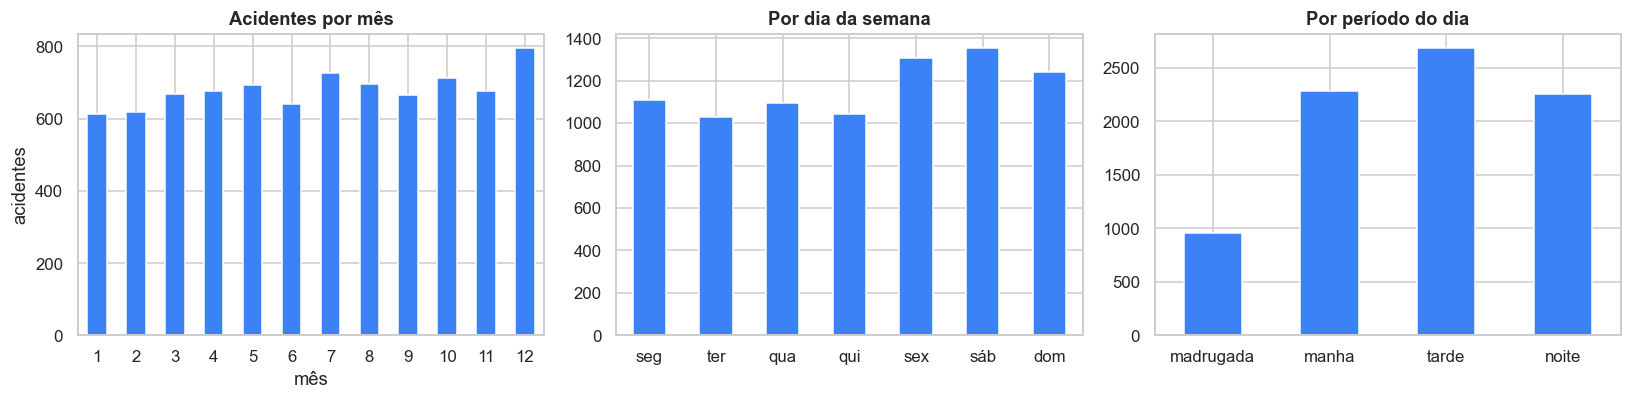

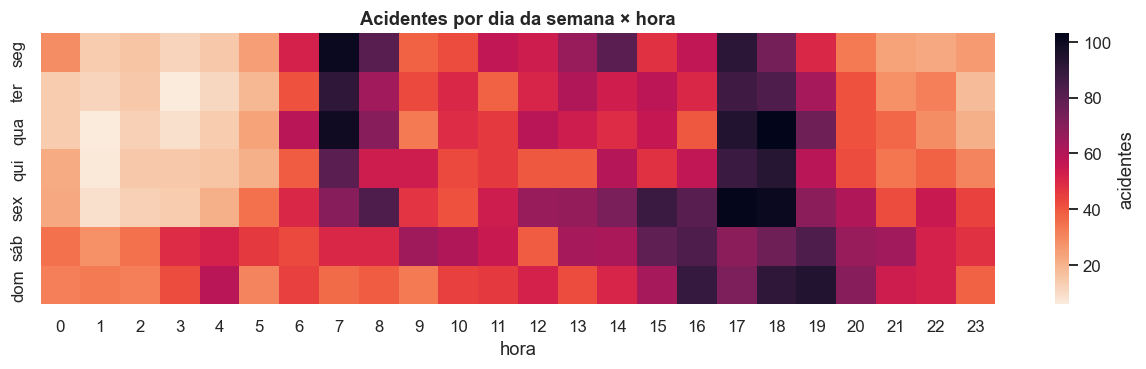

In [4]:
nomes_dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.8))
acidentes.groupby(acidentes["data"].dt.month).size().plot.bar(ax=eixos[0], color="#3b82f6")
eixos[0].set(title="Acidentes por mês", xlabel="mês", ylabel="acidentes")
(acidentes.groupby(acidentes["data"].dt.dayofweek).size().rename(dict(enumerate(nomes_dias)))
 .plot.bar(ax=eixos[1], color="#3b82f6"))
eixos[1].set(title="Por dia da semana", xlabel="", ylabel="")
acidentes["periodo"].value_counts().reindex(list(config.PERIODOS)).plot.bar(ax=eixos[2], color="#3b82f6")
eixos[2].set(title="Por período do dia", xlabel="", ylabel="")
for e in eixos:
    e.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

calor = (acidentes.assign(dia=acidentes["data"].dt.dayofweek)
         .pivot_table(index="dia", columns="hora", values="id", aggfunc="count", fill_value=0)
         .rename(index=dict(enumerate(nomes_dias))))
plt.figure(figsize=(14, 3.2))
sns.heatmap(calor, cmap="rocket_r", cbar_kws={"label": "acidentes"})
plt.title("Acidentes por dia da semana × hora")
plt.xlabel("hora")
plt.ylabel("")
plt.show()

In [5]:
# taxa de "período com acidente" por tipo de dia (na base, que tem também os períodos sem acidente)
tipo_dia = np.select(
    [base["feriado"] == 1, base["vespera_ou_pos_feriado"] == 1, base["fim_de_semana"] == 1],
    ["feriado", "véspera/pós-feriado", "fim de semana"], "dia útil comum")
taxa_dia = base.groupby(tipo_dia)[ALVO].agg(["mean", "size"]).rename(columns={"mean": "taxa", "size": "linhas"})
taxa_dia["vs. dia útil"] = taxa_dia["taxa"] / taxa_dia.loc["dia útil comum", "taxa"]
display(taxa_dia.sort_values("taxa", ascending=False))

,taxa,linhas,vs. dia útil
fim de semana,0.0247,89280,1.1933
véspera/pós-feriado,0.0221,23040,1.0709
feriado,0.0221,12480,1.0700
dia útil comum,0.0207,225600,1.0000


**O que isso mostra:** os acidentes crescem ao longo do ano (612 em janeiro → 795 em dezembro) e se concentram na sexta, no sábado e no domingo (1.241–1.353 contra ~1.030–1.110 nos dias úteis). A **tarde** tem 33% dos acidentes e a madrugada só 12%; os picos de hora são 17h–18h (volta do trabalho) e 7h. Na base completa, um período de fim de semana tem **19% mais chance** de ter acidente que um dia útil comum (2,47% × 2,07%); feriados e vésperas ficam só ~7% acima. O padrão segue o **tráfego**, não um efeito "perigoso" da data em si.

### 1.3 Onde: BRs e concentração nos trechos

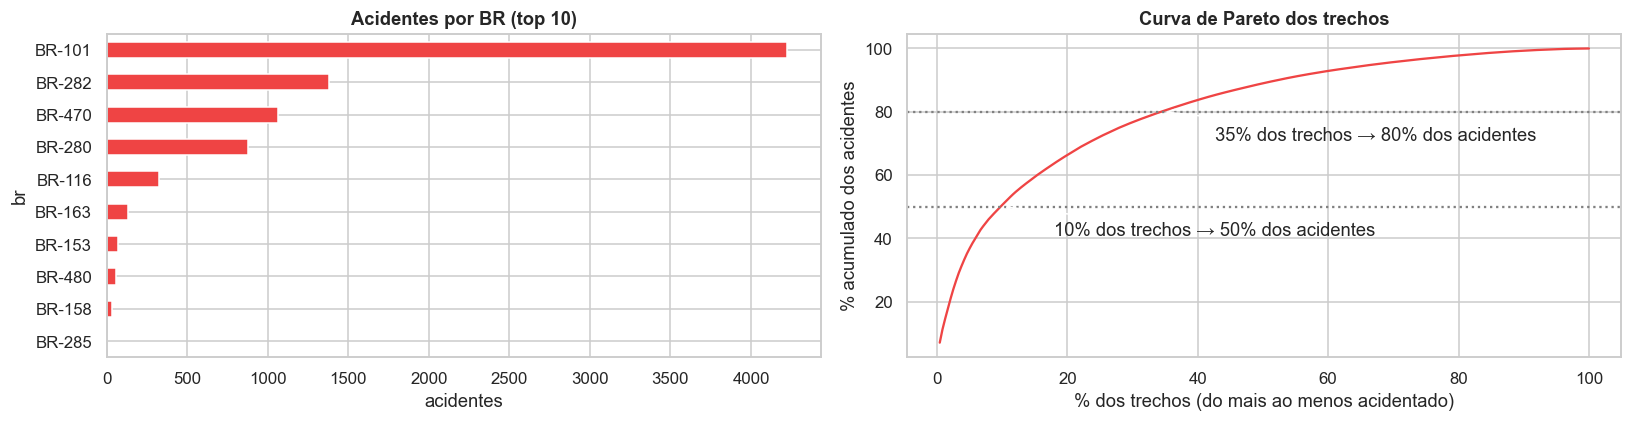

,br,trecho_km,municipio,acidentes,mortos
trecho_id,,,,,
101-200,101,200,SAO JOSE,575,10.0000
101-210,101,210,PALHOCA,341,4.0000
101-130,101,130,BALNEARIO CAMBORIU,279,8.0000
101-190,101,190,BIGUACU,261,8.0000
282-0,282,0,FLORIANOPOLIS,260,5.0000
101-110,101,110,ITAJAI,241,7.0000
101-120,101,120,ITAJAI,217,8.0000
101-140,101,140,ITAPEMA,202,8.0000
280-20,280,20,ARAQUARI,176,3.0000


In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 4))
acidentes["br"].value_counts().head(10).sort_values().rename(lambda b: f"BR-{b}").plot.barh(ax=eixos[0], color="#ef4444")
eixos[0].set(title="Acidentes por BR (top 10)", xlabel="acidentes")

por_trecho = acidentes.groupby("trecho_id").size().sort_values(ascending=False)
acumulado = por_trecho.cumsum() / por_trecho.sum()
fracao_trechos = np.arange(1, len(por_trecho) + 1) / len(por_trecho)
eixos[1].plot(fracao_trechos * 100, acumulado.values * 100, color="#ef4444")
for alvo in (0.5, 0.8):
    pct = fracao_trechos[np.searchsorted(acumulado.values, alvo)] * 100
    eixos[1].axhline(alvo * 100, ls=":", color="gray")
    eixos[1].annotate(f"{pct:.0f}% dos trechos → {alvo:.0%} dos acidentes", (pct, alvo * 100),
                      xytext=(pct + 8, alvo * 100 - 9), arrowprops={"arrowstyle": "->"})
eixos[1].set(title="Curva de Pareto dos trechos", xlabel="% dos trechos (do mais ao menos acidentado)",
             ylabel="% acumulado dos acidentes")
plt.tight_layout()
plt.show()

top = trechos.set_index("trecho_id").loc[por_trecho.index[:15], ["br", "trecho_km", "municipio", "acidentes", "mortos"]]
display(top)

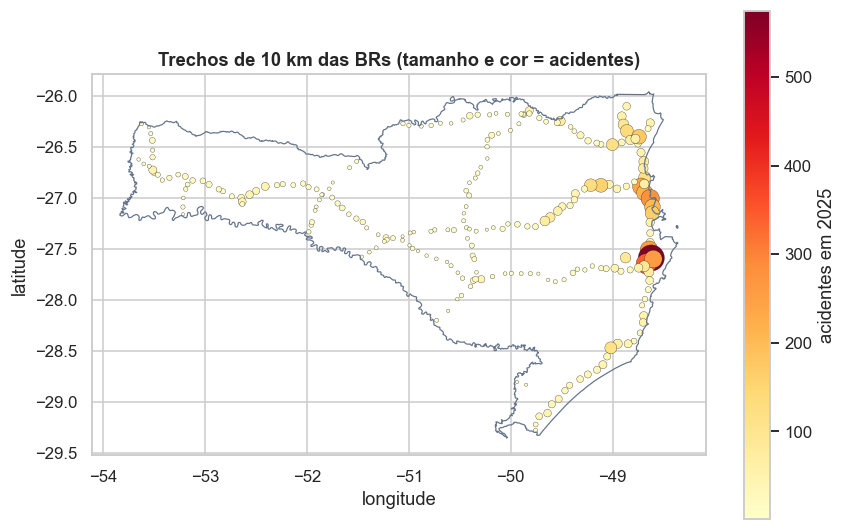

In [7]:
import json
contorno = json.loads(Path("frontend/public/sc.geojson").read_text())["features"][0]["geometry"]
poligonos = [contorno["coordinates"]] if contorno["type"] == "Polygon" else contorno["coordinates"]

fig, ax = plt.subplots(figsize=(9, 6))
for p in poligonos:
    x, y = zip(*p[0])
    ax.plot(x, y, color="#64748b", lw=0.8)
pontos = ax.scatter(trechos["lon"], trechos["lat"], c=trechos["acidentes"], s=trechos["acidentes"] / 2 + 4,
                    cmap="YlOrRd", edgecolor="k", linewidth=0.2)
plt.colorbar(pontos, label="acidentes em 2025")
ax.set(title="Trechos de 10 km das BRs (tamanho e cor = acidentes)", xlabel="longitude", ylabel="latitude")
ax.set_aspect("equal")
plt.show()

**O que isso mostra:** o risco é muito concentrado: **10% dos trechos (24) reúnem metade dos acidentes** e 35% dos trechos (83) somam 80%. Só a BR-101 tem 52% dos acidentes, seguida da BR-282 (17%), BR-470 (13%) e BR-280 (11%). Os trechos mais críticos estão na Grande Florianópolis e no litoral norte (BR-101 km 200 em São José: 575 acidentes, 1,6 por dia). Isso explica por que o histórico do trecho domina o modelo.

### 1.4 Como: tipo de acidente e gravidade

In [8]:
por_tipo = (acidentes.groupby("tipo_acidente")
            .agg(acidentes=("id", "size"), mortos=("mortos", "sum"), com_morte=("mortos", lambda s: (s > 0).mean()))
            .sort_values("acidentes", ascending=False))
por_tipo["% dos acidentes"] = por_tipo["acidentes"] / por_tipo["acidentes"].sum()
display(por_tipo.head(10).style.format({"% dos acidentes": "{:.1%}", "com_morte": "{:.1%}"}))

,acidentes,mortos,com_morte,% dos acidentes
tipo_acidente,,,,
Colisão traseira,1679,49.000000,2.7%,20.5%
Colisão transversal,1270,35.000000,2.0%,15.5%
Colisão lateral mesmo sentido,1167,15.000000,1.3%,14.3%
Saída de leito carroçável,944,35.000000,3.5%,11.5%
Tombamento,748,29.000000,3.5%,9.1%
Colisão com objeto,655,31.000000,4.4%,8.0%
Colisão frontal,516,150.000000,22.7%,6.3%
Queda de ocupante de veículo,284,3.000000,1.1%,3.5%
Atropelamento de Pedestre,254,63.000000,24.0%,3.1%


**O que isso mostra:** colisões traseiras, transversais e laterais somam metade dos acidentes, mas raramente matam (1–3% com morte). Já a **colisão frontal** (6% dos acidentes, 22,7% com morte) e o **atropelamento** (3%, 24% com morte) respondem juntos por **49% das mortes**. Um modelo de gravidade teria features e trechos críticos bem diferentes dos de frequência.

### 1.5 Clima (Open-Meteo)

O clima vem de uma reanálise medida **em todos os dias** — o campo de clima do boletim da PRF só existe quando
houve acidente e não pode ser usado (vazamento).

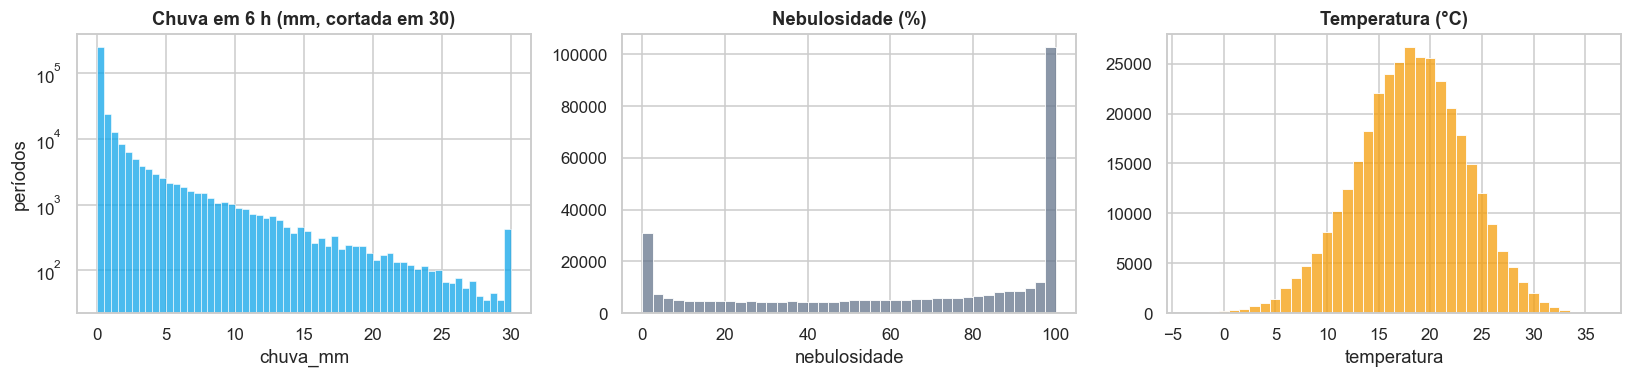

,taxa,periodos,% dos períodos
categoria_clima,,,
ceu_claro,0.0223,135567,0.3869
nublado,0.0200,143118,0.4084
chuva,0.0257,60490,0.1726
chuva_forte,0.0191,11225,0.0320


In [9]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(base["chuva_mm"].clip(upper=30), bins=60, ax=eixos[0], color="#0ea5e9")
eixos[0].set(title="Chuva em 6 h (mm, cortada em 30)", yscale="log", ylabel="períodos")
sns.histplot(base["nebulosidade"], bins=40, ax=eixos[1], color="#64748b")
eixos[1].set(title="Nebulosidade (%)", ylabel="")
sns.histplot(base["temperatura"], bins=40, ax=eixos[2], color="#f59e0b")
eixos[2].set(title="Temperatura (°C)", ylabel="")
plt.tight_layout()
plt.show()

base["categoria_clima"] = [clima.categoria_do_clima(c, n) for c, n in zip(base["chuva_mm"], base["nebulosidade"])]
taxa_clima = (base.groupby("categoria_clima")[ALVO].agg(taxa="mean", periodos="size")
              .reindex(list(config.CLIMA_CATEGORIAS)))
taxa_clima["% dos períodos"] = taxa_clima["periodos"] / taxa_clima["periodos"].sum()
display(taxa_clima)

**O que isso mostra:** períodos de **chuva forte** (3% do total) têm a **menor** taxa de acidente (1,91%), abaixo do céu claro (2,23%), enquanto chuva moderada tem a maior (2,57%). A leitura mais provável é que, com tempo muito ruim, menos gente viaja: o alvo mede "algum acidente no trecho", não o risco por veículo. Sem volume de tráfego, o clima fica confundido com a exposição.

### 1.6 Desbalanceamento do alvo

In [10]:
print(base[ALVO].value_counts(normalize=True).rename({0: "sem acidente", 1: "com acidente"}).to_string())
print(f"\ntreino: {treino[ALVO].mean():.2%} positivos | teste: {teste[ALVO].mean():.2%} positivos")

teve_acidente
sem acidente   0.9782
com acidente   0.0218

treino: 2.15% positivos | teste: 2.27% positivos


Com ~2% de positivos, a **acurácia** não serve (prever sempre "sem acidente" acerta ~98%). Por isso o estudo usa
**ROC-AUC** (o modelo ordena bem os períodos de risco?), **PR-AUC** (precisão × recall na classe rara — o chute
aleatório vale a própria taxa base) e **Brier** (as probabilidades estão bem calibradas?).

## 2. Correlação

Sobre as 16 features numéricas do modelo e o alvo, no **treino** (para não olhar o teste).

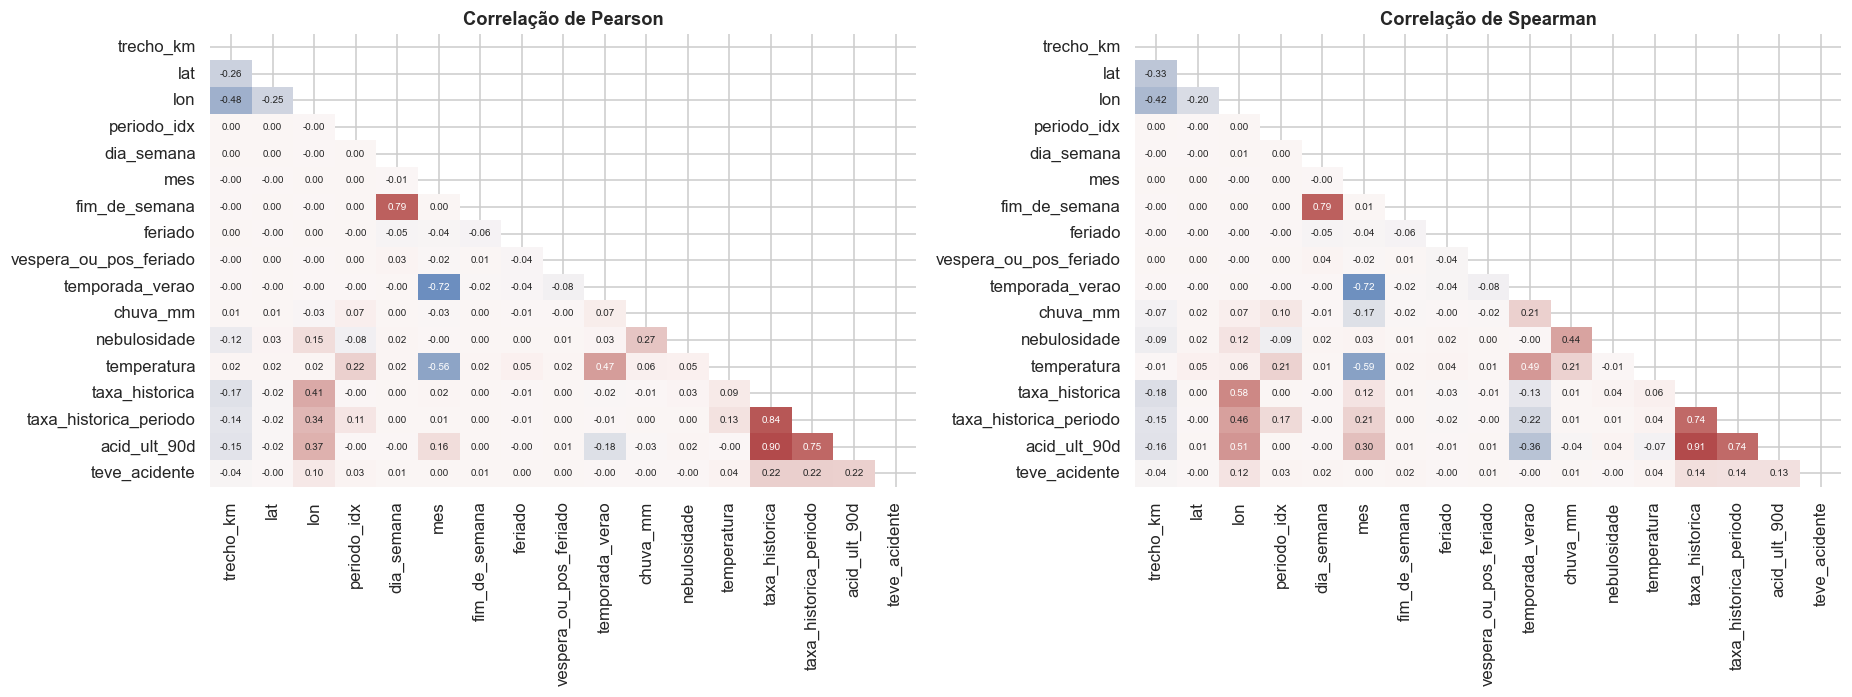

In [11]:
corr_p = treino[NUMS + [ALVO]].corr(method="pearson")
corr_s = treino[NUMS + [ALVO]].sample(80_000, random_state=SEMENTE).corr(method="spearman")
mascara = np.triu(np.ones_like(corr_p, dtype=bool))
fig, eixos = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, c, nome in [(eixos[0], corr_p, "Pearson"), (eixos[1], corr_s, "Spearman")]:
    sns.heatmap(c, mask=mascara, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
                annot_kws={"size": 6.5}, ax=ax, cbar=False)
    ax.set_title(f"Correlação de {nome}")
plt.tight_layout()
plt.show()

In [12]:
pares = (corr_p.loc[NUMS, NUMS].where(~np.tril(np.ones((len(NUMS),) * 2, dtype=bool)))
         .stack().rename("pearson").to_frame())
pares["|r|"] = pares["pearson"].abs()
display(pares.sort_values("|r|", ascending=False).head(10))

pearson    |r|
taxa_historica         acid_ult_90d             0.9020 0.9020
                       taxa_historica_periodo   0.8361 0.8361
dia_semana             fim_de_semana            0.7906 0.7906
taxa_historica_periodo acid_ult_90d             0.7541 0.7541
mes                    temporada_verao         -0.7217 0.7217
                       temperatura             -0.5646 0.5646
trecho_km              lon                     -0.4770 0.4770
temporada_verao        temperatura              0.4718 0.4718
lon                    taxa_historica           0.4077 0.4077
                       acid_ult_90d             0.3694 0.3694

### 2.1 Relação de cada feature com o alvo

- **Ponto-bisserial** = Pearson entre a feature e o alvo binário: mede só relação **linear**.
- **Informação mútua** captura qualquer dependência (inclusive não linear), mas não tem sinal.

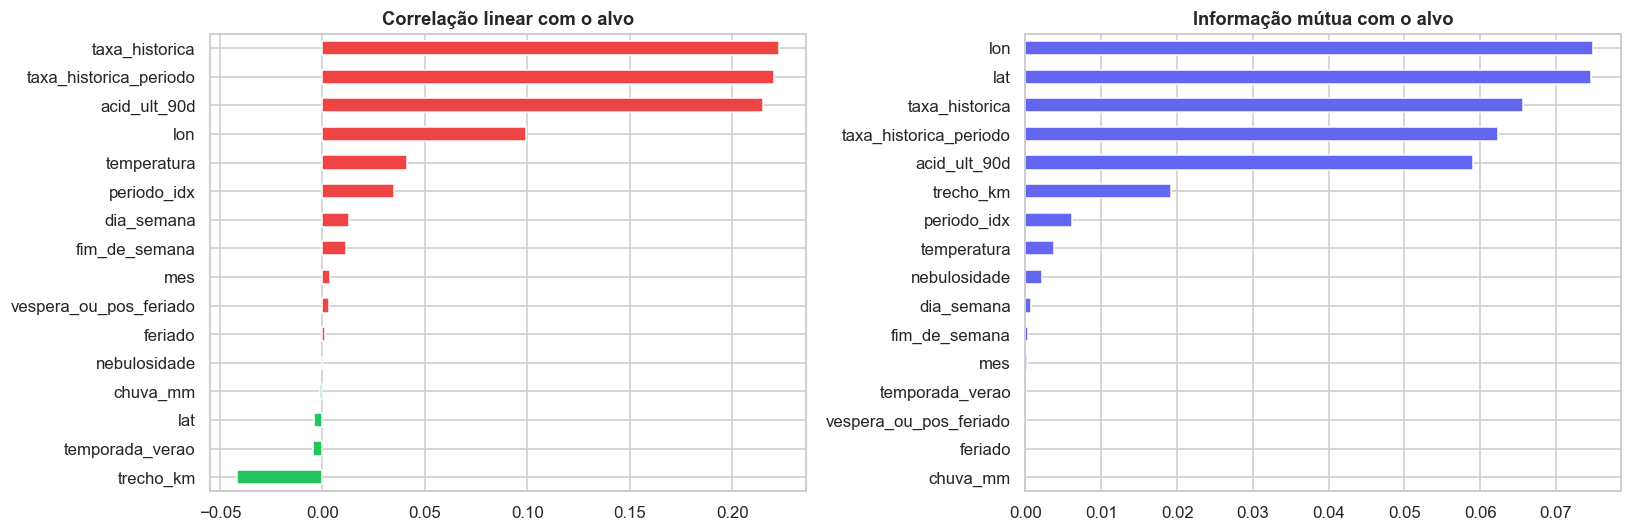

,ponto-bisserial,informação mútua
lon,0.0992,0.0749
lat,-0.0042,0.0746
taxa_historica,0.2230,0.0656
taxa_historica_periodo,0.2202,0.0624
acid_ult_90d,0.2150,0.0590
trecho_km,-0.0414,0.0192
periodo_idx,0.0350,0.0062
temperatura,0.0412,0.0038
nebulosidade,-0.0003,0.0022
dia_semana,0.0132,0.0007


In [13]:
from sklearn.feature_selection import mutual_info_classif

amostra_mi = treino.groupby(ALVO, group_keys=False).apply(lambda g: g.sample(min(len(g), 40_000), random_state=SEMENTE))
mi = pd.Series(mutual_info_classif(amostra_mi[NUMS], amostra_mi[ALVO], random_state=SEMENTE,
                                   discrete_features=[treino[f].nunique() <= 12 for f in NUMS]), index=NUMS)
relacao = pd.DataFrame({"ponto-bisserial": corr_p.loc[NUMS, ALVO], "informação mútua": mi})

fig, eixos = plt.subplots(1, 2, figsize=(15, 5))
relacao["ponto-bisserial"].sort_values().plot.barh(ax=eixos[0], color=np.where(relacao["ponto-bisserial"].sort_values() > 0, "#ef4444", "#22c55e"))
eixos[0].set(title="Correlação linear com o alvo")
relacao["informação mútua"].sort_values().plot.barh(ax=eixos[1], color="#6366f1")
eixos[1].set(title="Informação mútua com o alvo")
plt.tight_layout()
plt.show()
display(relacao.sort_values("informação mútua", ascending=False))

### 2.2 Multicolinearidade (VIF)

O **VIF** de uma feature é `1 / (1 − R²)` da regressão dela contra todas as outras. VIF > 5–10 indica que ela é
quase uma combinação das demais — informação redundante, que é exatamente o que o PCA comprime.

In [14]:
from sklearn.linear_model import LinearRegression

amostra_vif = treino[NUMS].sample(100_000, random_state=SEMENTE)
vif = {}
for f in NUMS:
    outras = [o for o in NUMS if o != f]
    r2 = LinearRegression().fit(amostra_vif[outras], amostra_vif[f]).score(amostra_vif[outras], amostra_vif[f])
    vif[f] = 1 / max(1 - r2, 1e-9)
vif = pd.Series(vif, name="VIF").sort_values(ascending=False)
display(vif.to_frame().style.format("{:.1f}").background_gradient(cmap="Reds", vmin=1, vmax=10))

,VIF
taxa_historica,8.9
acid_ult_90d,6.5
taxa_historica_periodo,3.5
fim_de_semana,2.7
dia_semana,2.7
mes,2.5
temporada_verao,2.3
lon,1.9
temperatura,1.7
trecho_km,1.6


### 2.3 Categóricas: BR e delegacia (Cramér's V com o alvo)

In [15]:
def cramers_v(x, y):
    tabela = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabela, correction=False)[0]
    return np.sqrt(chi2 / (tabela.values.sum() * (min(tabela.shape) - 1)))

display(pd.Series({c: cramers_v(treino[c], treino[ALVO]) for c in CATS}, name="Cramér's V").to_frame())

,Cramér's V
br,0.1184
delegacia,0.1322


**O que isso mostra:**

- **Redundância forte no histórico do trecho:** `taxa_historica` × `acid_ult_90d` (r = 0,90) e × `taxa_historica_periodo` (0,84). VIF de 8,9 e 6,5: são quase a mesma informação.
- Outros pares esperados: `dia_semana` × `fim_de_semana` (0,79) e `mes` × `temporada_verao` (−0,72). As demais features (clima, feriado, período) são praticamente independentes entre si (VIF ≈ 1).
- **Com o alvo**, as relações lineares são fracas (o maior ponto-bisserial é 0,22, das três de histórico). A informação mútua mostra que **lat/lon** carregam tanta informação quanto o histórico (0,075 × 0,066), mas de forma **não linear** (a correlação linear de `lat` com o alvo é ~0): o risco depende de *qual* lugar, não de "mais ao norte = mais risco". Isso favorece árvores sobre modelos lineares.
- Clima, feriado e mês têm informação mútua ~0 isoladamente; BR e delegacia têm associação fraca (Cramér's V 0,12–0,13).

## 3. PCA exploratório

PCA nas 16 features numéricas **padronizadas** (média 0, desvio 1 — sem isso as de maior escala, como
temperatura e km, dominariam). Ajustado **só no treino**. O PCA não olha o alvo: ele busca as direções de
maior variância, que não são necessariamente as mais úteis para prever acidente.

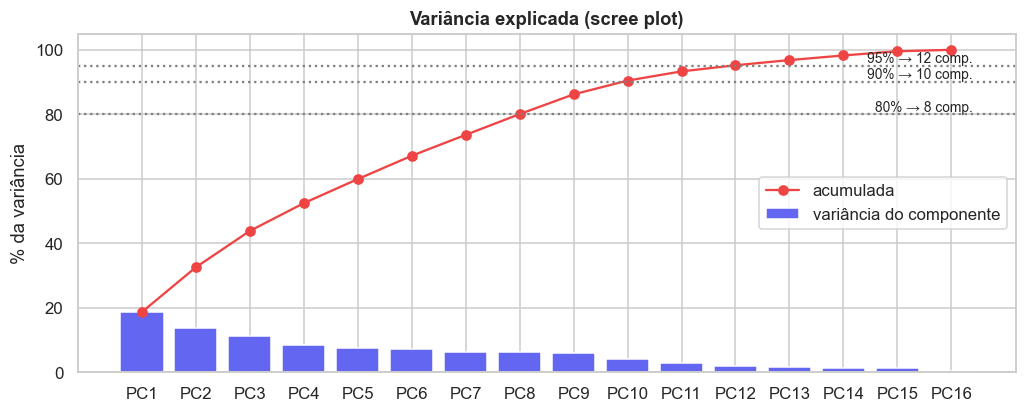

componentes necessários: {'80%': 8, '90%': 10, '95%': 12}


In [16]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

escala = StandardScaler().fit(treino[NUMS])
pca = PCA(random_state=SEMENTE).fit(escala.transform(treino[NUMS]))
var = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i + 1}" for i in range(len(NUMS))])
acum = var.cumsum()
N_COMP = {p: int(np.searchsorted(acum.values, p) + 1) for p in (0.8, 0.9, 0.95)}

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(var.index, var.values * 100, color="#6366f1", label="variância do componente")
ax.plot(var.index, acum.values * 100, "o-", color="#ef4444", label="acumulada")
for p, n in N_COMP.items():
    ax.axhline(p * 100, ls=":", color="gray")
    ax.text(len(NUMS) - 0.6, p * 100 + 1, f"{p:.0%} → {n} comp.", ha="right", fontsize=9)
ax.set(title="Variância explicada (scree plot)", ylabel="% da variância")
ax.legend(loc="center right")
plt.show()
print("componentes necessários:", {f"{p:.0%}": n for p, n in N_COMP.items()})

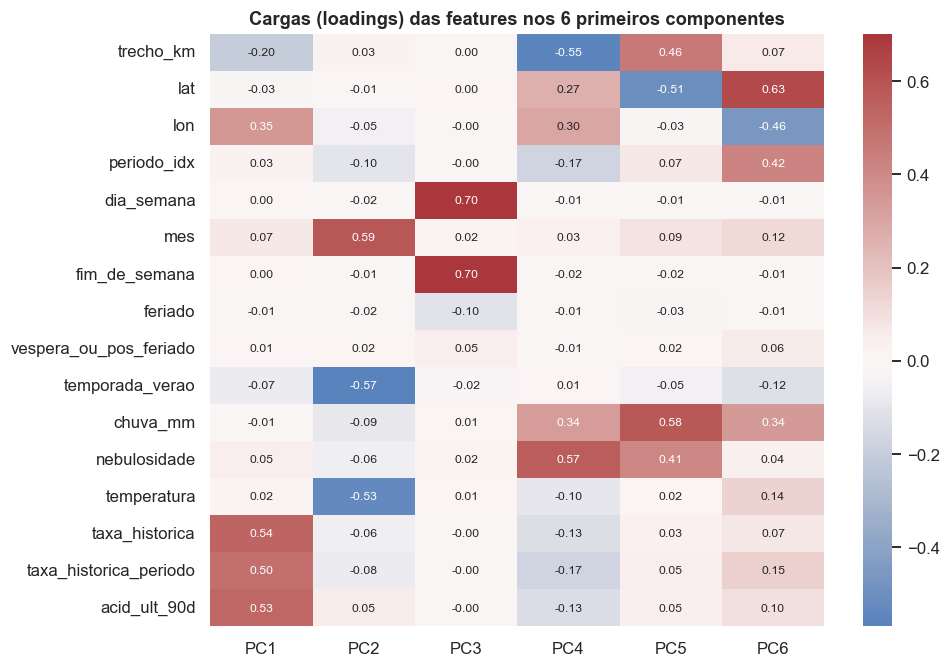

PC1 (18.7%): taxa_historica (+0.54), acid_ult_90d (+0.53), taxa_historica_periodo (+0.50)
PC2 (13.9%): mes (+0.59), temporada_verao (-0.57), temperatura (-0.53)
PC3 (11.3%): fim_de_semana (+0.70), dia_semana (+0.70), feriado (-0.10)
PC4 (8.6%): nebulosidade (+0.57), trecho_km (-0.55), chuva_mm (+0.34)
PC5 (7.5%): chuva_mm (+0.58), lat (-0.51), trecho_km (+0.46)
PC6 (7.2%): lat (+0.63), lon (-0.46), periodo_idx (+0.42)


In [17]:
cargas = pd.DataFrame(pca.components_[:6].T, index=NUMS, columns=[f"PC{i + 1}" for i in range(6)])
plt.figure(figsize=(9, 7))
sns.heatmap(cargas, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Cargas (loadings) das features nos 6 primeiros componentes")
plt.show()
for pc in cargas.columns:
    principais = cargas[pc].abs().sort_values(ascending=False).index[:3]
    print(f"{pc} ({var[pc]:.1%}): " + ", ".join(f"{f} ({cargas.loc[f, pc]:+.2f})" for f in principais))

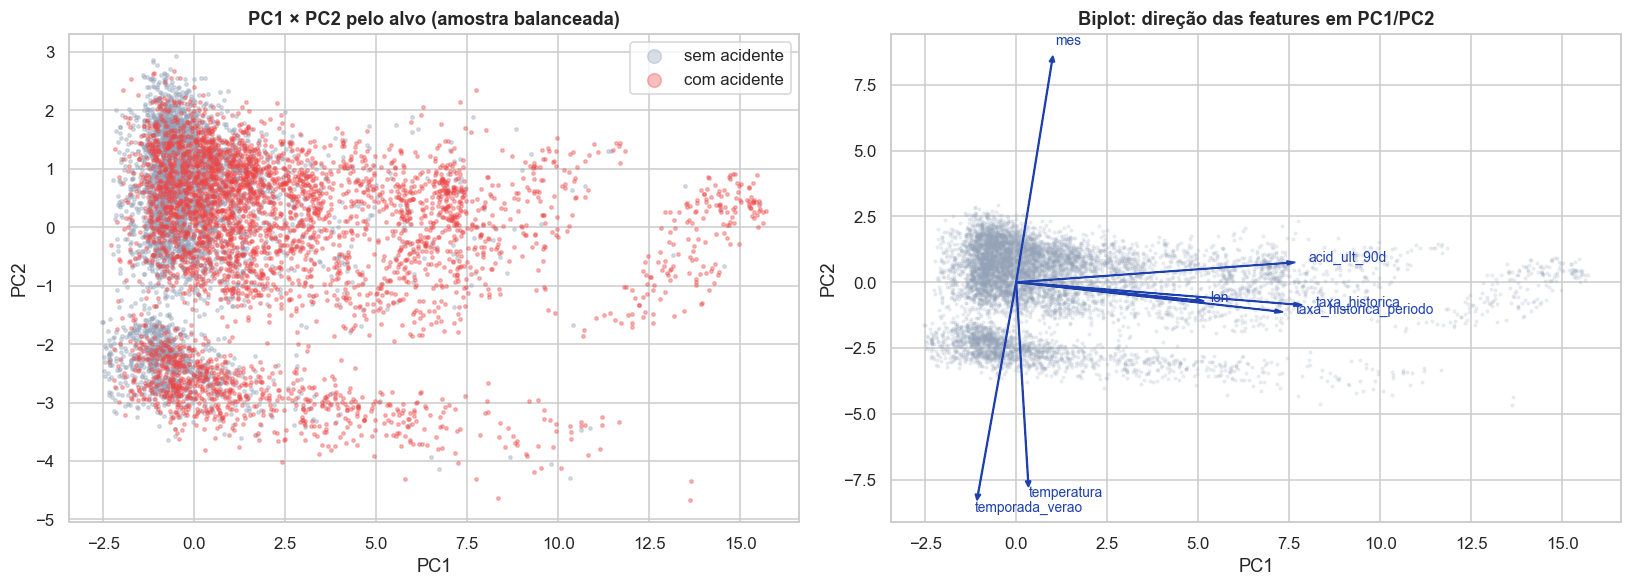

In [18]:
amostra_pca = treino.groupby(ALVO, group_keys=False).apply(lambda g: g.sample(4_000, random_state=SEMENTE))
proj = pca.transform(escala.transform(amostra_pca[NUMS]))[:, :2]

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))
for classe, cor, rotulo in [(0, "#94a3b8", "sem acidente"), (1, "#ef4444", "com acidente")]:
    m = amostra_pca[ALVO].values == classe
    eixos[0].scatter(proj[m, 0], proj[m, 1], s=5, alpha=0.35, color=cor, label=rotulo)
eixos[0].set(title="PC1 × PC2 pelo alvo (amostra balanceada)", xlabel="PC1", ylabel="PC2")
eixos[0].legend(markerscale=4)

# biplot: setas das 6 features com maior carga em PC1/PC2
eixos[1].scatter(proj[:, 0], proj[:, 1], s=3, alpha=0.15, color="#94a3b8")
escala_seta = np.abs(proj).max() * 0.9
for f in (cargas[["PC1", "PC2"]] ** 2).sum(axis=1).sort_values(ascending=False).index[:7]:
    x, y = cargas.loc[f, "PC1"] * escala_seta, cargas.loc[f, "PC2"] * escala_seta
    eixos[1].arrow(0, 0, x, y, color="#1e40af", width=0.02, head_width=0.15)
    eixos[1].text(x * 1.08, y * 1.08, f, color="#1e40af", fontsize=9)
eixos[1].set(title="Biplot: direção das features em PC1/PC2", xlabel="PC1", ylabel="PC2")
plt.tight_layout()
plt.show()

**O que isso mostra:** a variância está **espalhada**: são precisos 8 componentes para 80%, 10 para 90% e 12 (de 16) para 95%; não há um punhado de eixos que resuma tudo. Os componentes são bem interpretáveis: **PC1 (18,7%) = histórico do trecho** (as três features redundantes juntas), **PC2 (13,9%) = estação do ano** (mês, verão, temperatura), **PC3 (11,3%) = fim de semana**, PC4/PC5 = clima misturado com posição na BR, PC6 = localização e período. Na projeção PC1 × PC2, os pontos com **PC1 alto** (acima de ~2,5, os trechos de histórico alto) são quase todos períodos com acidente, e o PC2 separa dois blocos (verão × resto do ano). Mas a grande maioria dos pontos fica perto da origem, onde as duas classes **se sobrepõem**: só o PC1 ajuda a separar, e ele é basicamente o histórico do trecho que o modelo já usa direto.

## 4. Modelos sem PCA × com PCA

Mesma base, mesmo split temporal (teste = out–dez/2025) e as mesmas métricas do projeto (`avaliar`).

| Família | Sem PCA | Com PCA |
|---|---|---|
| **Regressão logística** | numéricas padronizadas + BR/delegacia em one-hot | numéricas padronizadas → **PCA** + BR/delegacia em one-hot |
| **HistGradientBoosting** | o modelo do projeto (`novo_modelo`): categóricas nativas e restrição monotônica no histórico | numéricas padronizadas → **PCA** + BR/delegacia nativas (a restrição monotônica deixa de fazer sentido nos componentes) |

O número de componentes é o que explica **95%** da variância (seção 3). Depois, uma curva testa de 2 até
todos os componentes.

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

N95 = N_COMP[0.95]
y_tr, y_te = treino[ALVO].values, teste[ALVO].values
categorias = {c: sorted(trechos[c].astype(str).unique()) for c in CATS}


def logistica(n_comp=None):
    numericas = [("escala", StandardScaler())] + ([("pca", PCA(n_comp, random_state=SEMENTE))] if n_comp else [])
    prep = ColumnTransformer([("num", Pipeline(numericas), NUMS),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CATS)])
    return Pipeline([("prep", prep), ("modelo", LogisticRegression(max_iter=2000, C=1.0))])


def X_logistica(df):
    return df[NUMS + CATS].astype({c: str for c in CATS})


def hgb_com_pca(n_comp):
    """Escala + PCA ajustados no treino; devolve (modelo, função que transforma um DataFrame)."""
    esc = StandardScaler().fit(treino[NUMS])
    p = PCA(n_comp, random_state=SEMENTE).fit(esc.transform(treino[NUMS]))
    nomes = [f"PC{i + 1}" for i in range(n_comp)]

    def transformar(df):
        X = pd.DataFrame(p.transform(esc.transform(df[NUMS])), columns=nomes, index=df.index)
        for c in CATS:
            X[c] = pd.Categorical(df[c].astype(str), categories=categorias[c])
        return X

    modelo = novo_modelo(nomes + CATS).fit(transformar(treino), y_tr)
    return modelo, transformar


resultados, probs = {}, {}

def registrar(nome, n_entradas, segundos, p):
    probs[nome] = p
    resultados[nome] = {**avaliar(y_te, p), "features de entrada": n_entradas, "treino (s)": round(segundos, 1)}

inicio = time.time(); m = logistica().fit(X_logistica(treino), y_tr)
registrar("Logística sem PCA", len(NUMS) + len(CATS), time.time() - inicio, m.predict_proba(X_logistica(teste))[:, 1])

inicio = time.time(); m = logistica(N95).fit(X_logistica(treino), y_tr)
registrar(f"Logística com PCA ({N95})", N95 + len(CATS), time.time() - inicio, m.predict_proba(X_logistica(teste))[:, 1])

inicio = time.time(); m = novo_modelo(FEATS).fit(preparar_X(treino, categorias, FEATS), y_tr)
registrar("HistGB sem PCA (projeto)", len(FEATS), time.time() - inicio, m.predict_proba(preparar_X(teste, categorias, FEATS))[:, 1])

inicio = time.time(); m, transf = hgb_com_pca(N95)
registrar(f"HistGB com PCA ({N95})", N95 + len(CATS), time.time() - inicio, m.predict_proba(transf(teste))[:, 1])

resultados["Só histórico do trecho (ingênuo)"] = {**avaliar(y_te, teste["taxa_historica_periodo"].clip(0, 1)),
                                                  "features de entrada": 1, "treino (s)": 0.0}
resultados["Chute aleatório"] = {"roc_auc": 0.5, "pr_auc": round(y_te.mean(), 4), "brier": round(float(np.mean((y_te - y_te.mean()) ** 2)), 5),
                                 "features de entrada": 0, "treino (s)": 0.0}
tabela = pd.DataFrame(resultados).T
display(tabela.style.format({"roc_auc": "{:.4f}", "pr_auc": "{:.4f}", "brier": "{:.5f}", "treino (s)": "{:.1f}",
                             "features de entrada": "{:.0f}"})
        .highlight_max(subset=["roc_auc", "pr_auc"], color="#bbf7d0")
        .highlight_min(subset=["brier"], color="#bbf7d0"))

,roc_auc,pr_auc,brier,features de entrada,treino (s)
Logística sem PCA,0.7991,0.1424,0.02095,18,0.2
Logística com PCA (12),0.7990,0.1424,0.02088,14,0.2
HistGB sem PCA (projeto),0.8165,0.1531,0.02060,18,1.3
HistGB com PCA (12),0.8098,0.1492,0.02067,14,0.9
Só histórico do trecho (ingênuo),0.8052,0.1459,0.02067,1,0.0
Chute aleatório,0.5000,0.0227,0.02222,0,0.0


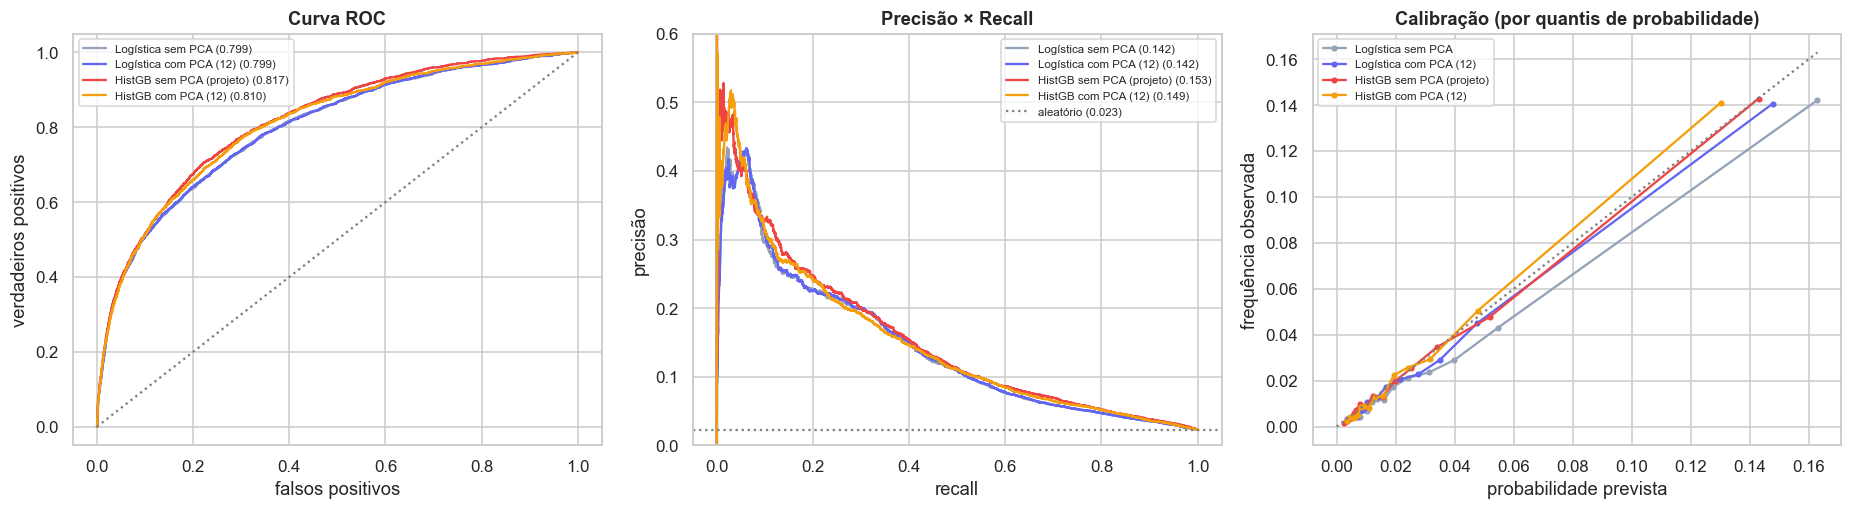

In [20]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve

cores = dict(zip(probs, ["#94a3b8", "#6366f1", "#ef4444", "#f59e0b"]))
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.8))
for nome, p in probs.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    eixos[0].plot(fpr, tpr, color=cores[nome], label=f"{nome} ({resultados[nome]['roc_auc']:.3f})")
    prec, rec, _ = precision_recall_curve(y_te, p)
    eixos[1].plot(rec, prec, color=cores[nome], label=f"{nome} ({resultados[nome]['pr_auc']:.3f})")
    frac, media = calibration_curve(y_te, p, n_bins=15, strategy="quantile")
    eixos[2].plot(media, frac, "o-", ms=3, color=cores[nome], label=nome)
eixos[0].plot([0, 1], [0, 1], ":", color="gray")
eixos[0].set(title="Curva ROC", xlabel="falsos positivos", ylabel="verdadeiros positivos")
eixos[1].axhline(y_te.mean(), ls=":", color="gray", label=f"aleatório ({y_te.mean():.3f})")
eixos[1].set(title="Precisão × Recall", xlabel="recall", ylabel="precisão", ylim=(0, 0.6))
lim = max(m.max() for m in [calibration_curve(y_te, p, n_bins=15, strategy="quantile")[1] for p in probs.values()])
eixos[2].plot([0, lim], [0, lim], ":", color="gray")
eixos[2].set(title="Calibração (por quantis de probabilidade)", xlabel="probabilidade prevista", ylabel="frequência observada")
for e in eixos:
    e.legend(fontsize=7.5)
plt.tight_layout()
plt.show()

### 4.1 Quantos componentes? Curva de desempenho

Treina de novo as duas famílias com 2, 4, 6, … componentes (e com todos — PCA sem descartar nada, só rotacionando
os eixos) e compara com o mesmo modelo **sem PCA** (linhas tracejadas).

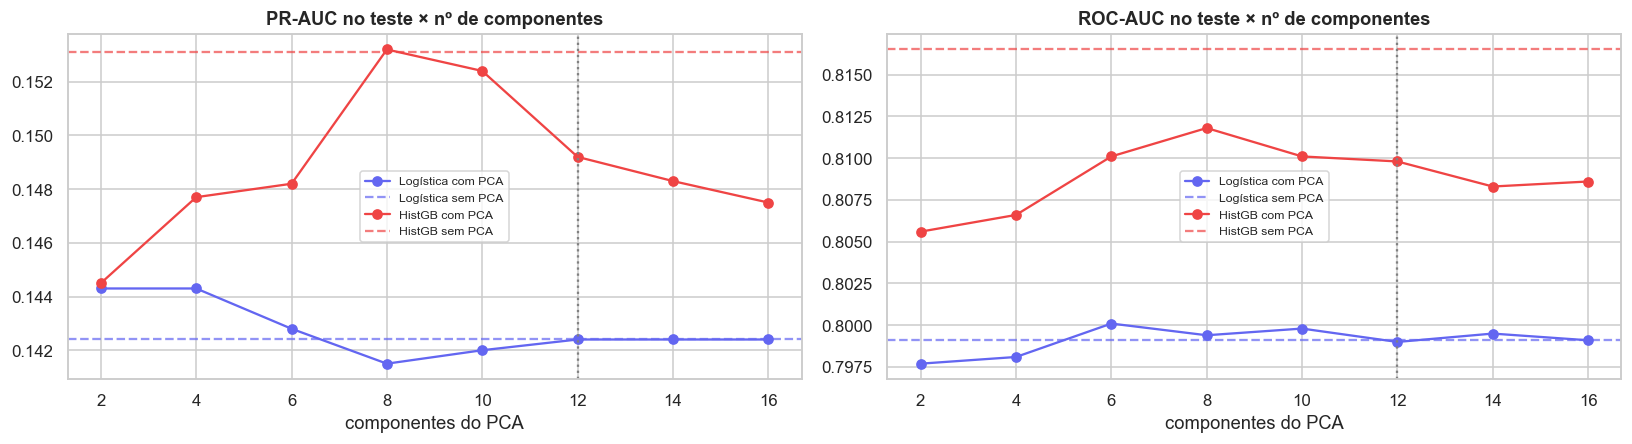

pr_auc           roc_auc          
família     HistGB Logística  HistGB Logística
componentes                                   
2           0.1445    0.1443  0.8056    0.7977
4           0.1477    0.1443  0.8066    0.7981
6           0.1482    0.1428  0.8101    0.8001
8           0.1532    0.1415  0.8118    0.7994
10          0.1524    0.1420  0.8101    0.7998
12          0.1492    0.1424  0.8098    0.7990
14          0.1483    0.1424  0.8083    0.7995
16          0.1475    0.1424  0.8086    0.7991

In [21]:
curva = []
for n in sorted({2, 4, 6, 8, 10, 12, 14, len(NUMS)}):
    m = logistica(n).fit(X_logistica(treino), y_tr)
    curva.append({"componentes": n, "família": "Logística", **avaliar(y_te, m.predict_proba(X_logistica(teste))[:, 1])})
    m, transf = hgb_com_pca(n)
    curva.append({"componentes": n, "família": "HistGB", **avaliar(y_te, m.predict_proba(transf(teste))[:, 1])})
curva = pd.DataFrame(curva)

fig, eixos = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, metrica in zip(eixos, ["pr_auc", "roc_auc"]):
    for familia, cor, sem in [("Logística", "#6366f1", "Logística sem PCA"), ("HistGB", "#ef4444", "HistGB sem PCA (projeto)")]:
        d = curva[curva["família"] == familia]
        ax.plot(d["componentes"], d[metrica], "o-", color=cor, label=f"{familia} com PCA")
        ax.axhline(resultados[sem][metrica], ls="--", color=cor, alpha=0.7, label=f"{familia} sem PCA")
    ax.axvline(N95, ls=":", color="gray")
    ax.set(title=metrica.upper().replace("_", "-") + " no teste × nº de componentes", xlabel="componentes do PCA")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
display(curva.pivot(index="componentes", columns="família", values=["pr_auc", "roc_auc"]))

**O que isso mostra:**

- **Logística: o PCA não muda nada.** Sem PCA, ROC-AUC 0,7991 e PR-AUC 0,1424; com 12 componentes, 0,7990 e 0,1424 (Brier um pouco melhor, 0,02088 × 0,02095). Com regularização L2 e só 16 features, a multicolinearidade não estava atrapalhando, e o PCA só rotaciona os mesmos dados. A curva mostra que com só 2 ou 4 componentes a PR-AUC é até um pouco maior (0,144 × 0,142): a logística só aproveita o sinal linear do histórico, que o PC1 já carrega, e os outros componentes quase só trazem ruído.
- **HistGB: o PCA piora.** O modelo do projeto sem PCA tem ROC-AUC **0,8165** e PR-AUC **0,1531**; com 12 componentes cai para 0,8098 e 0,1492, ficando quase igual à referência ingênua (0,8052 / 0,1459). Na curva, o melhor caso é com **8 componentes**: a PR-AUC empata com o modelo sem PCA (0,1532 × 0,1531), mas a ROC-AUC continua abaixo (0,8118 × 0,8165). Em nenhum número de componentes o PCA melhora o HGB. A árvore já lida bem com features correlacionadas e precisa dos cortes em **lat/lon e no histórico originais**; o PCA mistura essas variáveis em combinações lineares e a árvore perde esses cortes simples (além de perder a restrição monotônica do histórico).
- **HGB > logística** com ou sem PCA (0,8165 × 0,7991 de ROC-AUC), coerente com a informação mútua não linear de lat/lon vista na seção 2.
- Nota: as métricas do HGB sem PCA diferem na 4ª casa das do projeto (0,8167 / 0,1544) porque este notebook roda no `.venv` da raiz (scikit-learn 1.6) e o backend no 1.9.

## 5. Resumo

**O que isso mostra:**

- **Exploratória:** os acidentes se concentram em poucos trechos (10% dos trechos = 50% dos acidentes, metade só na BR-101), no fim de semana e no fim da tarde; colisões frontais e atropelamentos são poucos, mas causam metade das mortes. A chuva forte aparece com *menos* acidentes por falta de dado de tráfego.
- **Correlação:** as três features de histórico são redundantes (r até 0,90, VIF até 8,9) e a relação com o alvo é sobretudo **não linear** (lat/lon).
- **PCA exploratório:** variância espalhada (12 de 16 componentes para 95%), com componentes interpretáveis (histórico, estação, fim de semana), mas que não separam as classes.
- **Com × sem PCA:** na logística o PCA é neutro; no HistGB ele **piora** (−0,007 de ROC-AUC, −0,004 de PR-AUC) e tira a interpretabilidade.
- **Para o projeto:** manter o **HistGB sem PCA**. Se for preciso simplificar, é melhor tirar uma das features redundantes (ex.: `acid_ult_90d`) do que aplicar PCA. Os ganhos maiores devem vir de dados novos (tráfego/VMDa, mais anos da PRF), não de transformar as features atuais.